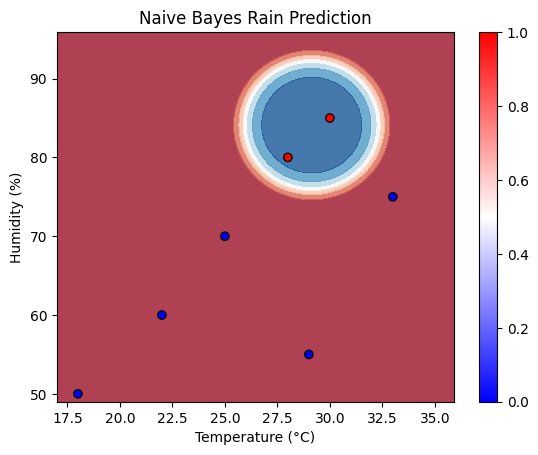

,Temperature (°C),Humidity (%),Rained
0,30,85,1
1,25,70,0
2,20,90,1
3,22,60,0
4,35,95,1
5,28,80,1
6,18,50,0
7,33,75,0
8,31,65,1
9,29,55,0


In [5]:
from IPython import get_ipython
from IPython.display import display
# %%
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
# Load the dataset
df = pd.read_csv('weather_prediction_data.csv')
# Features and Labels
X=df[['Temperature (°C)', 'Humidity (%)']].values # Corrected line
y = df['Rained'].values # Assuming 'Rained' is your target column
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
# Train the Naive Bayes model
model = GaussianNB() # Assign to variable
model.fit(X_train, y_train)
# Create a meshgrid for plotting
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1 # Corrected indexing
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1 # Corrected indexing
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))
# Predict probabilities on the meshgrid
Z = model.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]
Z = Z.reshape(xx.shape) # Assign to variable
# Plotting
plt.contourf(xx, yy, Z, alpha=0.8, cmap='RdBu')
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, edgecolors='k', cmap='bwr')
plt.xlabel('Temperature (°C)')
plt.ylabel('Humidity (%)')
plt.title('Naive Bayes Rain Prediction')
plt.colorbar()
plt.show()
from IPython.display import display, HTML

# Assuming 'df' is your Pandas DataFrame
html_table = df.to_html()
display(HTML(html_table))